# 04 — BRISC Leakage-Aware Split Preparation

This notebook constructs reproducible leakage-controlled dataset splits for
the BRISC 2025 classification task.

The official BRISC training and testing directories are preserved unchanged.
Rather than deleting or moving raw images, exclusion and split decisions are
stored as metadata.

Primary objectives:

1. Compute a systematic decoded-image content fingerprint for all
   classification images.
2. identify confirmed content duplication across the official train/test split.
3. Exclude cross-split duplicate-linked records from the training pool while
   preserving the official test set.
4. Prevent duplicate image groups from being split between training and
   validation subsets.
5. Construct reproducible training and validation partitions.
6. Preserve class and MRI-plane distributions as far as practicable.
7. Export definitive split manifests for downstream preprocessing and modelling.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from PIL import Image

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI"
)

DATASET_ROOT = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "brisc2025"
)

MANIFEST_PATH = (
    DATASET_ROOT /
    "manifest.csv"
)

INTERIM_ROOT = (
    PROJECT_ROOT /
    "data" /
    "interim"
)

PROCESSED_ROOT = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

OUTPUTS_ROOT = (
    PROJECT_ROOT /
    "outputs"
)

TABLES_ROOT = (
    OUTPUTS_ROOT /
    "tables"
)

FIGURES_ROOT = (
    OUTPUTS_ROOT /
    "figures"
)

# Create output directories if necessary
INTERIM_ROOT.mkdir(parents=True, exist_ok=True)
PROCESSED_ROOT.mkdir(parents=True, exist_ok=True)
TABLES_ROOT.mkdir(parents=True, exist_ok=True)
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Manifest exists:", MANIFEST_PATH.exists())

Project root: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI
Dataset root: C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\raw\brisc2025
Manifest exists: True


In [2]:
manifest_df = pd.read_csv(MANIFEST_PATH)

classification_df = (
    manifest_df[
        manifest_df["task"] == "classification"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Manifest records:", len(manifest_df))
print("Classification records:", len(classification_df))

print("\nOFFICIAL SPLIT COUNTS")
print("-" * 50)

display(
    classification_df[
        ["split", "tumor_label"]
    ]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

print("\nTotal by split:")
display(
    classification_df["split"]
    .value_counts()
    .rename("count")
    .to_frame()
)

Manifest records: 15586
Classification records: 6000

OFFICIAL SPLIT COUNTS
--------------------------------------------------


count
split tumor_label       
test  glioma         254
      meningioma     306
      no_tumor       140
      pituitary      300
train glioma        1147
      meningioma    1329
      no_tumor      1067
      pituitary     1457


Total by split:


,count
split,
train,5000
test,1000


In [3]:
required_columns = [
    "relative_path",
    "filename",
    "split",
    "tumor_label",
    "plane_label"
]

missing_columns = [
    col for col in required_columns
    if col not in classification_df.columns
]

print("Required columns:", required_columns)
print("Missing columns:", missing_columns)

if missing_columns:
    raise ValueError(
        f"Required manifest columns are missing: {missing_columns}"
    )

print("\nClassification manifest is ready.")

Required columns: ['relative_path', 'filename', 'split', 'tumor_label', 'plane_label']
Missing columns: []

Classification manifest is ready.


## 2. Decoded-Image Content Fingerprinting

File-level SHA-256 hashes can fail to identify duplicate images when identical
pixel content is stored using different JPEG metadata or encoding.

Therefore, every classification image is decoded, converted consistently to RGB,
and fingerprinted using its dimensions and decoded RGB pixel bytes.

Images sharing the resulting fingerprint represent exactly identical decoded
visual content under this normalization.

In [4]:
def decoded_rgb_fingerprint(image_path):
    """
    Compute SHA-256 fingerprint from:
    - RGB-normalized decoded pixels
    - image width
    - image height
    """

    with Image.open(image_path) as img:
        rgb = img.convert("RGB")
        arr = np.asarray(rgb)

    height, width = arr.shape[:2]

    hasher = hashlib.sha256()

    # Include dimensions to avoid accidental ambiguity
    hasher.update(
        f"{width}x{height}|RGB|".encode("utf-8")
    )

    hasher.update(arr.tobytes())

    return hasher.hexdigest()


fingerprints = []

print("Computing decoded RGB fingerprints...")
print("Images to process:", len(classification_df))

for i, row in classification_df.iterrows():

    image_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    fingerprint = decoded_rgb_fingerprint(image_path)

    fingerprints.append(fingerprint)

    if (i + 1) % 500 == 0:
        print(
            f"Processed {i + 1}/{len(classification_df)}"
        )


classification_df["decoded_rgb_sha256"] = fingerprints

print("\nFingerprinting complete.")
print("Records fingerprinted:", len(classification_df))
print(
    "Unique decoded fingerprints:",
    classification_df["decoded_rgb_sha256"].nunique()
)

Computing decoded RGB fingerprints...
Images to process: 6000
Processed 500/6000
Processed 1000/6000
Processed 1500/6000
Processed 2000/6000
Processed 2500/6000
Processed 3000/6000
Processed 3500/6000
Processed 4000/6000
Processed 4500/6000
Processed 5000/6000
Processed 5500/6000
Processed 6000/6000

Fingerprinting complete.
Records fingerprinted: 6000
Unique decoded fingerprints: 5856


In [5]:
fingerprint_path = (
    INTERIM_ROOT /
    "classification_decoded_rgb_fingerprints.csv"
)

classification_df.to_csv(
    fingerprint_path,
    index=False
)

print("Decoded fingerprint table saved to:")
print(fingerprint_path)

print("\nFile exists:", fingerprint_path.exists())

Decoded fingerprint table saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_decoded_rgb_fingerprints.csv

File exists: True


In [6]:
# ------------------------------------------------------------
# Analyze duplicate groups using decoded RGB fingerprints
# ------------------------------------------------------------

fingerprint_group_sizes = (
    classification_df
    .groupby("decoded_rgb_sha256")
    .size()
    .rename("group_size")
)

duplicate_fingerprints = (
    fingerprint_group_sizes[
        fingerprint_group_sizes > 1
    ]
    .index
)

duplicate_records_df = classification_df[
    classification_df["decoded_rgb_sha256"].isin(
        duplicate_fingerprints
    )
].copy()

print("DECODED RGB DUPLICATE ANALYSIS")
print("-" * 70)

print(
    "Duplicate-content groups:",
    len(duplicate_fingerprints)
)

print(
    "Records belonging to duplicate groups:",
    len(duplicate_records_df)
)

print(
    "Excess duplicate records beyond one representative per group:",
    len(classification_df)
    - classification_df["decoded_rgb_sha256"].nunique()
)


# ------------------------------------------------------------
# Determine whether duplicate groups occur in train, test,
# or across both splits
# ------------------------------------------------------------

group_split_summary = (
    duplicate_records_df
    .groupby("decoded_rgb_sha256")
    .agg(
        group_size=("filename", "size"),
        train_count=(
            "split",
            lambda x: (x == "train").sum()
        ),
        test_count=(
            "split",
            lambda x: (x == "test").sum()
        ),
        label_count=(
            "tumor_label",
            "nunique"
        )
    )
)

train_only_groups = group_split_summary[
    (group_split_summary["train_count"] > 0) &
    (group_split_summary["test_count"] == 0)
]

test_only_groups = group_split_summary[
    (group_split_summary["train_count"] == 0) &
    (group_split_summary["test_count"] > 0)
]

cross_split_groups = group_split_summary[
    (group_split_summary["train_count"] > 0) &
    (group_split_summary["test_count"] > 0)
]

conflicting_label_groups = group_split_summary[
    group_split_summary["label_count"] > 1
]


print("\nDUPLICATE GROUP LOCATION")
print("-" * 70)

print("Train-only duplicate groups:", len(train_only_groups))
print("Test-only duplicate groups:", len(test_only_groups))
print("Cross-split duplicate groups:", len(cross_split_groups))

print(
    "Duplicate groups with conflicting tumor labels:",
    len(conflicting_label_groups)
)


# ------------------------------------------------------------
# Records affected specifically by cross-split duplication
# ------------------------------------------------------------

cross_split_fingerprints = cross_split_groups.index

cross_split_records_df = classification_df[
    classification_df["decoded_rgb_sha256"].isin(
        cross_split_fingerprints
    )
].copy()

cross_split_train_df = cross_split_records_df[
    cross_split_records_df["split"] == "train"
].copy()

cross_split_test_df = cross_split_records_df[
    cross_split_records_df["split"] == "test"
].copy()


print("\nCROSS-SPLIT DUPLICATION")
print("-" * 70)

print(
    "Affected training records:",
    len(cross_split_train_df)
)

print(
    "Affected testing records:",
    len(cross_split_test_df)
)

print(
    "Total cross-split affected records:",
    len(cross_split_records_df)
)


print("\nAFFECTED TEST RECORDS BY CLASS")
print("-" * 70)

display(
    cross_split_test_df[
        "tumor_label"
    ]
    .value_counts()
    .rename("affected_test_records")
    .to_frame()
)


print("\nAFFECTED TRAIN RECORDS BY CLASS")
print("-" * 70)

display(
    cross_split_train_df[
        "tumor_label"
    ]
    .value_counts()
    .rename("affected_train_records")
    .to_frame()
)

DECODED RGB DUPLICATE ANALYSIS
----------------------------------------------------------------------
Duplicate-content groups: 134
Records belonging to duplicate groups: 278
Excess duplicate records beyond one representative per group: 144

DUPLICATE GROUP LOCATION
----------------------------------------------------------------------
Train-only duplicate groups: 31
Test-only duplicate groups: 5
Cross-split duplicate groups: 98
Duplicate groups with conflicting tumor labels: 0

CROSS-SPLIT DUPLICATION
----------------------------------------------------------------------
Affected training records: 104
Affected testing records: 101
Total cross-split affected records: 205

AFFECTED TEST RECORDS BY CLASS
----------------------------------------------------------------------


,affected_test_records
tumor_label,
meningioma,96
pituitary,5



AFFECTED TRAIN RECORDS BY CLASS
----------------------------------------------------------------------


,affected_train_records
tumor_label,
meningioma,97
pituitary,7


## 3. Confirmed Cross-Split Duplicate Content

Systematic decoded-RGB fingerprinting identified exact duplicate visual content
within the BRISC classification dataset.

Across 6,000 classification records:

- 5,856 unique decoded-image fingerprints were observed.
- 134 decoded-content duplicate groups were identified.
- 31 duplicate groups occurred only within the official training split.
- 5 duplicate groups occurred only within the official testing split.
- 98 duplicate groups contained records from both the official training and
  testing splits.

The cross-split groups contain:

- **104 training records**
- **101 testing records**

No decoded duplicate group contained conflicting tumor labels.

Cross-split duplication is highly class-dependent. Of the 101 affected official
test records, 96 are meningioma and 5 are pituitary. The corresponding training
records consist of 97 meningioma and 7 pituitary images.

These results exactly reproduce the affected-record counts previously obtained
through the independent SHA-256, perceptual-hash, and pixel-level duplicate
verification workflow.

For the primary leakage-controlled evaluation protocol, the official test set
will remain unchanged. All 104 training records whose decoded image content also
occurs in the official test set will instead be excluded from the model-development
training pool.

No raw BRISC files are deleted or modified; exclusions are represented only
through reproducible metadata.

In [7]:
# ------------------------------------------------------------
# Create definitive leakage-control metadata
# ------------------------------------------------------------

classification_df["cross_split_duplicate"] = (
    classification_df["decoded_rgb_sha256"].isin(
        cross_split_fingerprints
    )
)

classification_df["exclude_from_training"] = (
    (classification_df["split"] == "train") &
    classification_df["cross_split_duplicate"]
)

# Records that will be excluded from model-development training
training_exclusion_df = classification_df[
    classification_df["exclude_from_training"]
].copy()

# Official test records that are involved in the same content groups
affected_test_audit_df = classification_df[
    (classification_df["split"] == "test") &
    classification_df["cross_split_duplicate"]
].copy()


print("LEAKAGE-CONTROL METADATA")
print("-" * 70)

print(
    "Training records marked for exclusion:",
    len(training_exclusion_df)
)

print(
    "Official test records retained but flagged for audit:",
    len(affected_test_audit_df)
)

print(
    "Raw files deleted:",
    0
)


# ------------------------------------------------------------
# Save audit tables
# ------------------------------------------------------------

training_exclusion_path = (
    INTERIM_ROOT /
    "classification_cross_split_training_exclusions.csv"
)

affected_test_path = (
    INTERIM_ROOT /
    "classification_cross_split_affected_test_audit.csv"
)

cross_split_group_path = (
    INTERIM_ROOT /
    "classification_cross_split_decoded_duplicate_groups.csv"
)

training_exclusion_df.to_csv(
    training_exclusion_path,
    index=False
)

affected_test_audit_df.to_csv(
    affected_test_path,
    index=False
)

cross_split_groups.reset_index().to_csv(
    cross_split_group_path,
    index=False
)


print("\nSaved:")
print(training_exclusion_path)
print(affected_test_path)
print(cross_split_group_path)

print("\nFiles exist:")
print(training_exclusion_path.exists())
print(affected_test_path.exists())
print(cross_split_group_path.exists())

LEAKAGE-CONTROL METADATA
----------------------------------------------------------------------
Training records marked for exclusion: 104
Official test records retained but flagged for audit: 101
Raw files deleted: 0

Saved:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_cross_split_training_exclusions.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_cross_split_affected_test_audit.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_cross_split_decoded_duplicate_groups.csv

Files exist:
True
True
True


## 4. Within-Training Duplicate Groups

After removing records linked to the official test set, the remaining
model-development pool may still contain duplicate image content entirely within
the official training split.

These records do not create leakage into the official test set. However, they
could create leakage between the newly constructed training and validation
subsets if identical images were assigned independently.

Therefore, decoded-image fingerprints are treated as grouping identifiers during
train/validation split construction. All records sharing the same decoded-image
fingerprint must remain in the same subset.

Before constructing the split, the remaining duplicate groups are audited for
class-label and MRI-plane consistency.

In [8]:
# ------------------------------------------------------------
# Construct leakage-controlled model-development pool
# ------------------------------------------------------------

development_pool_df = classification_df[
    (classification_df["split"] == "train") &
    (~classification_df["exclude_from_training"])
].copy()

development_pool_df = development_pool_df.reset_index(drop=True)

print("LEAKAGE-CONTROLLED DEVELOPMENT POOL")
print("-" * 70)

print("Official training records:", 5000)
print("Cross-split exclusions:", 104)
print(
    "Remaining development-pool records:",
    len(development_pool_df)
)

print(
    "Unique decoded fingerprints:",
    development_pool_df["decoded_rgb_sha256"].nunique()
)


# ------------------------------------------------------------
# Identify duplicate groups remaining inside development pool
# ------------------------------------------------------------

dev_group_summary = (
    development_pool_df
    .groupby("decoded_rgb_sha256")
    .agg(
        group_size=("filename", "size"),
        label_count=("tumor_label", "nunique"),
        plane_count=("plane_label", "nunique")
    )
)

dev_duplicate_groups = dev_group_summary[
    dev_group_summary["group_size"] > 1
].copy()

print("\nWITHIN-DEVELOPMENT DUPLICATE AUDIT")
print("-" * 70)

print(
    "Duplicate-content groups remaining:",
    len(dev_duplicate_groups)
)

print(
    "Records belonging to duplicate groups:",
    int(dev_duplicate_groups["group_size"].sum())
)

print(
    "Excess duplicate records:",
    int(
        (dev_duplicate_groups["group_size"] - 1).sum()
    )
)

print(
    "Duplicate groups with conflicting tumor labels:",
    int((dev_duplicate_groups["label_count"] > 1).sum())
)

print(
    "Duplicate groups with conflicting MRI-plane labels:",
    int((dev_duplicate_groups["plane_count"] > 1).sum())
)


print("\nDUPLICATE GROUP SIZE DISTRIBUTION")
print("-" * 70)

display(
    dev_duplicate_groups["group_size"]
    .value_counts()
    .sort_index()
    .rename("number_of_groups")
    .to_frame()
)


print("\nDEVELOPMENT POOL BY CLASS")
print("-" * 70)

display(
    development_pool_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)


print("\nDEVELOPMENT POOL BY CLASS AND PLANE")
print("-" * 70)

display(
    pd.crosstab(
        development_pool_df["tumor_label"],
        development_pool_df["plane_label"]
    )
)

LEAKAGE-CONTROLLED DEVELOPMENT POOL
----------------------------------------------------------------------
Official training records: 5000
Cross-split exclusions: 104
Remaining development-pool records: 4896
Unique decoded fingerprints: 4864

WITHIN-DEVELOPMENT DUPLICATE AUDIT
----------------------------------------------------------------------
Duplicate-content groups remaining: 31
Records belonging to duplicate groups: 63
Excess duplicate records: 32
Duplicate groups with conflicting tumor labels: 0
Duplicate groups with conflicting MRI-plane labels: 11

DUPLICATE GROUP SIZE DISTRIBUTION
----------------------------------------------------------------------


,number_of_groups
group_size,
2,30
3,1



DEVELOPMENT POOL BY CLASS
----------------------------------------------------------------------


,records
tumor_label,
glioma,1147
meningioma,1232
no_tumor,1067
pituitary,1450



DEVELOPMENT POOL BY CLASS AND PLANE
----------------------------------------------------------------------


plane_label,axial,coronal,sagittal
tumor_label,,,
glioma,394,430,323
meningioma,361,407,464
no_tumor,352,310,405
pituitary,424,505,521


## 4.1 Audit of Duplicate Groups with Conflicting MRI-Plane Metadata

A subset of exact decoded-image duplicate 11 groups contains records assigned to
different MRI-plane labels.

Because the underlying decoded image content is identical within each group,
these disagreements indicate metadata inconsistency or duplicated records with
different plane annotations. The correct anatomical plane cannot be inferred
from duplicate status alone.

These groups are inspected explicitly before final train/validation split
construction.

In [9]:
# ------------------------------------------------------------
# Inspect duplicate groups with conflicting MRI-plane labels
# ------------------------------------------------------------

plane_conflict_fingerprints = (
    dev_duplicate_groups[
        dev_duplicate_groups["plane_count"] > 1
    ]
    .index
)

plane_conflict_records_df = development_pool_df[
    development_pool_df["decoded_rgb_sha256"].isin(
        plane_conflict_fingerprints
    )
].copy()

plane_conflict_records_df["fingerprint_short"] = (
    plane_conflict_records_df["decoded_rgb_sha256"]
    .str[:12]
)

plane_conflict_records_df = (
    plane_conflict_records_df
    .sort_values(
        [
            "decoded_rgb_sha256",
            "tumor_label",
            "plane_label",
            "filename"
        ]
    )
)


print("PLANE-CONFLICT DUPLICATE GROUPS")
print("-" * 70)

print(
    "Groups with conflicting plane labels:",
    len(plane_conflict_fingerprints)
)

print(
    "Records involved:",
    len(plane_conflict_records_df)
)


print("\nPLANE COMBINATIONS BY DUPLICATE GROUP")
print("-" * 70)

plane_conflict_summary = (
    plane_conflict_records_df
    .groupby("decoded_rgb_sha256")
    .agg(
        records=("filename", "size"),
        tumor_label=("tumor_label", "first"),
        planes=(
            "plane_label",
            lambda x: ", ".join(sorted(set(x)))
        )
    )
    .reset_index()
)

plane_conflict_summary["fingerprint_short"] = (
    plane_conflict_summary["decoded_rgb_sha256"]
    .str[:12]
)

display(
    plane_conflict_summary[
        [
            "fingerprint_short",
            "records",
            "tumor_label",
            "planes"
        ]
    ]
)


print("\nINDIVIDUAL RECORDS")
print("-" * 70)

display(
    plane_conflict_records_df[
        [
            "fingerprint_short",
            "filename",
            "tumor_label",
            "plane_label",
            "relative_path"
        ]
    ]
)

PLANE-CONFLICT DUPLICATE GROUPS
----------------------------------------------------------------------
Groups with conflicting plane labels: 11
Records involved: 22

PLANE COMBINATIONS BY DUPLICATE GROUP
----------------------------------------------------------------------


,fingerprint_short,records,tumor_label,planes
0,1cb1d65c83ca,2,meningioma,"axial, coronal"
1,36be02c612f1,2,meningioma,"axial, sagittal"
2,38976d58721e,2,meningioma,"coronal, sagittal"
3,5f186e7e7543,2,meningioma,"axial, sagittal"
4,7bdd320367fa,2,meningioma,"axial, coronal"
5,9ce7f1c1ba1b,2,meningioma,"axial, coronal"
6,abc0b54c1caf,2,meningioma,"axial, sagittal"
7,bbeb9d74b258,2,meningioma,"axial, coronal"
8,c361f52bf37f,2,meningioma,"axial, coronal"
9,ca7caae35246,2,meningioma,"axial, coronal"



INDIVIDUAL RECORDS
----------------------------------------------------------------------


,fingerprint_short,filename,tumor_label,plane_label,relative_path
1236,1cb1d65c83ca,brisc2025_train_01238_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...
1586,1cb1d65c83ca,brisc2025_train_01649_me_co_t1.jpg,meningioma,coronal,classification_task\train\meningioma\brisc2025...
1404,36be02c612f1,brisc2025_train_01467_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...
2267,36be02c612f1,brisc2025_train_02365_me_sa_t1.jpg,meningioma,sagittal,classification_task\train\meningioma\brisc2025...
1508,38976d58721e,brisc2025_train_01571_me_co_t1.jpg,meningioma,coronal,classification_task\train\meningioma\brisc2025...
1915,38976d58721e,brisc2025_train_01997_me_sa_t1.jpg,meningioma,sagittal,classification_task\train\meningioma\brisc2025...
1393,5f186e7e7543,brisc2025_train_01456_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...
2188,5f186e7e7543,brisc2025_train_02286_me_sa_t1.jpg,meningioma,sagittal,classification_task\train\meningioma\brisc2025...
1238,7bdd320367fa,brisc2025_train_01240_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...
1588,7bdd320367fa,brisc2025_train_01651_me_co_t1.jpg,meningioma,coronal,classification_task\train\meningioma\brisc2025...


### Interpretation of MRI-Plane Metadata Conflicts

Eleven exact decoded-image duplicate groups contain inconsistent MRI-plane
metadata. All 11 groups belong to the meningioma class and each contains two
pixel-identical records assigned to different anatomical planes.

The observed conflicts comprise six axial–coronal groups, four
axial–sagittal groups, and one coronal–sagittal group.

Because the decoded image content within each group is identical, the differing
plane annotations cannot both be treated as independent reliable descriptions
of the image. The correct plane is therefore not inferred automatically.

These conflicts do not affect the classification target because no duplicate
group contains conflicting tumor labels.

For downstream preparation, one deterministic representative will be retained
per decoded-image fingerprint. Plane-conflicting groups will be explicitly
flagged in the metadata and will not be assigned an arbitrary plane for
stratification.

In [10]:
# ------------------------------------------------------------
# Build metadata for every unique decoded image in the
# leakage-controlled development pool
# ------------------------------------------------------------

def join_unique_sorted(values):
    return ", ".join(
        sorted(set(values.dropna().astype(str)))
    )


content_group_metadata = (
    development_pool_df
    .groupby("decoded_rgb_sha256")
    .agg(
        source_record_count=("filename", "size"),
        tumor_label_count=("tumor_label", "nunique"),
        plane_label_count=("plane_label", "nunique"),
        observed_tumor_labels=(
            "tumor_label",
            join_unique_sorted
        ),
        observed_plane_labels=(
            "plane_label",
            join_unique_sorted
        )
    )
    .reset_index()
)

content_group_metadata["plane_metadata_conflict"] = (
    content_group_metadata["plane_label_count"] > 1
)

print("UNIQUE-CONTENT GROUP METADATA")
print("-" * 70)

print(
    "Unique decoded-image groups:",
    len(content_group_metadata)
)

print(
    "Groups containing >1 source record:",
    int(
        (
            content_group_metadata["source_record_count"] > 1
        ).sum()
    )
)

print(
    "Groups with tumor-label conflicts:",
    int(
        (
            content_group_metadata["tumor_label_count"] > 1
        ).sum()
    )
)

print(
    "Groups with plane-label conflicts:",
    int(
        content_group_metadata[
            "plane_metadata_conflict"
        ].sum()
    )
)

UNIQUE-CONTENT GROUP METADATA
----------------------------------------------------------------------
Unique decoded-image groups: 4864
Groups containing >1 source record: 31
Groups with tumor-label conflicts: 0
Groups with plane-label conflicts: 11


In [11]:
# ------------------------------------------------------------
# Deterministically retain one representative per unique
# decoded-image fingerprint
# ------------------------------------------------------------

sorted_dev_df = (
    development_pool_df
    .sort_values(
        [
            "decoded_rgb_sha256",
            "relative_path"
        ]
    )
    .copy()
)

unique_development_df = (
    sorted_dev_df
    .drop_duplicates(
        subset="decoded_rgb_sha256",
        keep="first"
    )
    .copy()
)

# Merge group-level audit information onto representatives
unique_development_df = (
    unique_development_df
    .merge(
        content_group_metadata[
            [
                "decoded_rgb_sha256",
                "source_record_count",
                "observed_plane_labels",
                "plane_metadata_conflict"
            ]
        ],
        on="decoded_rgb_sha256",
        how="left"
    )
)

# Do not use an arbitrary plane label for conflicting groups
unique_development_df[
    "plane_for_stratification"
] = np.where(
    unique_development_df[
        "plane_metadata_conflict"
    ],
    "conflict",
    unique_development_df["plane_label"]
)

print("UNIQUE-CONTENT DEVELOPMENT POOL")
print("-" * 70)

print(
    "Input development records:",
    len(development_pool_df)
)

print(
    "Unique-content representatives:",
    len(unique_development_df)
)

print(
    "Redundant records removed from development metadata:",
    len(development_pool_df)
    - len(unique_development_df)
)

print(
    "Plane-conflict representatives:",
    int(
        unique_development_df[
            "plane_metadata_conflict"
        ].sum()
    )
)

print("\nCLASS DISTRIBUTION")
display(
    unique_development_df[
        "tumor_label"
    ]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

print("\nPLANE LABEL USED FOR STRATIFICATION")
display(
    unique_development_df[
        "plane_for_stratification"
    ]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

UNIQUE-CONTENT DEVELOPMENT POOL
----------------------------------------------------------------------
Input development records: 4896
Unique-content representatives: 4864
Redundant records removed from development metadata: 32
Plane-conflict representatives: 11

CLASS DISTRIBUTION


,records
tumor_label,
glioma,1147
meningioma,1219
no_tumor,1058
pituitary,1440



PLANE LABEL USED FOR STRATIFICATION


,records
plane_for_stratification,
axial,1520
conflict,11
coronal,1642
sagittal,1691


In [12]:
retained_paths = set(
    unique_development_df["relative_path"]
)

within_dev_duplicate_exclusions_df = (
    development_pool_df[
        ~development_pool_df[
            "relative_path"
        ].isin(retained_paths)
    ]
    .copy()
)

print("WITHIN-DEVELOPMENT REDUNDANT RECORDS")
print("-" * 70)

print(
    "Records not retained:",
    len(within_dev_duplicate_exclusions_df)
)

print("\nBy class:")
display(
    within_dev_duplicate_exclusions_df[
        "tumor_label"
    ]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)


within_dev_exclusion_path = (
    INTERIM_ROOT /
    "classification_within_development_duplicate_exclusions.csv"
)

unique_dev_path = (
    INTERIM_ROOT /
    "classification_unique_content_development_pool.csv"
)

plane_conflict_path = (
    INTERIM_ROOT /
    "classification_duplicate_plane_conflicts.csv"
)

within_dev_duplicate_exclusions_df.to_csv(
    within_dev_exclusion_path,
    index=False
)

unique_development_df.to_csv(
    unique_dev_path,
    index=False
)

plane_conflict_records_df.to_csv(
    plane_conflict_path,
    index=False
)

print("\nSaved:")
print(within_dev_exclusion_path)
print(unique_dev_path)
print(plane_conflict_path)

print("\nFiles exist:")
print(within_dev_exclusion_path.exists())
print(unique_dev_path.exists())
print(plane_conflict_path.exists())

WITHIN-DEVELOPMENT REDUNDANT RECORDS
----------------------------------------------------------------------
Records not retained: 32

By class:


,records
tumor_label,
meningioma,13
no_tumor,9
pituitary,10



Saved:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_within_development_duplicate_exclusions.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_unique_content_development_pool.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_duplicate_plane_conflicts.csv

Files exist:
True
True
True


## 5. Audit of Strong but Unconfirmed Cross-Split Similarity Candidates

The earlier integrity analysis identified a small set of train–test image pairs
with very high perceptual and normalized pixel similarity that were not proven
to be exact decoded-image duplicates.

These pairs were deliberately retained as *unconfirmed* rather than being
automatically classified as leakage.

Because the development pool has now undergone confirmed cross-split exclusion
and within-training exact-content deduplication, the earlier candidate list is
re-evaluated against the current unique-content development pool.

Only candidate pairs whose training member is still present in the development
pool remain relevant to the final split decision.

In [13]:
# ------------------------------------------------------------
# Load strong-but-unconfirmed candidates exported by Notebook 2
# ------------------------------------------------------------

unconfirmed_candidate_path = (
    INTERIM_ROOT /
    "classification_high_similarity_unconfirmed_candidates.csv"
)

print(
    "Candidate file exists:",
    unconfirmed_candidate_path.exists()
)

if not unconfirmed_candidate_path.exists():
    raise FileNotFoundError(
        "The strong-but-unconfirmed candidate file from Notebook 2 "
        "was not found."
    )

unconfirmed_candidates_df = pd.read_csv(
    unconfirmed_candidate_path
)

print(
    "Original strong-but-unconfirmed candidate pairs:",
    len(unconfirmed_candidates_df)
)

print(
    "Unique training images in original candidate pairs:",
    unconfirmed_candidates_df[
        "train_filename"
    ].nunique()
)

print(
    "Unique testing images in original candidate pairs:",
    unconfirmed_candidates_df[
        "test_filename"
    ].nunique()
)


# ------------------------------------------------------------
# Determine which candidate training images survived all exact
# duplicate-cleaning steps
# ------------------------------------------------------------

current_train_filenames = set(
    unique_development_df["filename"]
)

unconfirmed_candidates_df[
    "train_still_in_development_pool"
] = (
    unconfirmed_candidates_df[
        "train_filename"
    ].isin(current_train_filenames)
)

relevant_unconfirmed_df = (
    unconfirmed_candidates_df[
        unconfirmed_candidates_df[
            "train_still_in_development_pool"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


print("\nAFTER EXACT-CONTENT CLEANING")
print("-" * 70)

print(
    "Candidate pairs still relevant:",
    len(relevant_unconfirmed_df)
)

print(
    "Unique remaining training images involved:",
    relevant_unconfirmed_df[
        "train_filename"
    ].nunique()
)

print(
    "Unique official test images involved:",
    relevant_unconfirmed_df[
        "test_filename"
    ].nunique()
)

print(
    "Candidate pairs rendered irrelevant because "
    "their training image was already excluded:",
    len(unconfirmed_candidates_df)
    - len(relevant_unconfirmed_df)
)


print("\nRELEVANT CANDIDATES BY CLASS")
print("-" * 70)

display(
    relevant_unconfirmed_df[
        "tumor_label"
    ]
    .value_counts()
    .rename("candidate_pairs")
    .to_frame()
)


print("\nRELEVANT CANDIDATE METRICS")
print("-" * 70)

display(
    relevant_unconfirmed_df[
        [
            "train_filename",
            "test_filename",
            "tumor_label",
            "train_plane",
            "test_plane",
            "train_size",
            "test_size",
            "phash_distance",
            "rmse",
            "correlation"
        ]
    ]
    .sort_values(
        ["rmse", "correlation"],
        ascending=[True, False]
    )
)

Candidate file exists: True
Original strong-but-unconfirmed candidate pairs: 21
Unique training images in original candidate pairs: 14
Unique testing images in original candidate pairs: 13

AFTER EXACT-CONTENT CLEANING
----------------------------------------------------------------------
Candidate pairs still relevant: 4
Unique remaining training images involved: 2
Unique official test images involved: 4
Candidate pairs rendered irrelevant because their training image was already excluded: 17

RELEVANT CANDIDATES BY CLASS
----------------------------------------------------------------------


,candidate_pairs
tumor_label,
meningioma,4



RELEVANT CANDIDATE METRICS
----------------------------------------------------------------------


,train_filename,test_filename,tumor_label,train_plane,test_plane,train_size,test_size,phash_distance,rmse,correlation
0,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00257_me_ax_t1.jpg,meningioma,axial,axial,"(591, 650)","(528, 581)",0,0.004325,0.999897
1,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00267_me_ax_t1.jpg,meningioma,axial,axial,"(591, 650)","(591, 650)",0,0.005852,0.999842
2,brisc2025_train_01288_me_ax_t1.jpg,brisc2025_test_00299_me_ax_t1.jpg,meningioma,axial,axial,"(480, 480)","(480, 480)",0,0.009460,0.999696
3,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00316_me_ax_t1.jpg,meningioma,axial,axial,"(591, 650)","(214, 235)",2,0.012262,0.999176


## 5.1 Native-Resolution Verification of Remaining Similarity Candidates

Four high-similarity train–test candidate pairs remain relevant after exact
content cleaning.

These candidates are examined at their original native resolutions to determine
whether any are pixel-identical, whether equal-sized pairs remain highly similar
without resizing, and whether differences in image dimensions may explain why
they were not classified as exact decoded-content duplicates.

High similarity alone is not treated as proof of duplicate identity.

In [14]:
# ------------------------------------------------------------
# Native-resolution verification of the remaining candidates
# ------------------------------------------------------------

native_verification_records = []

for _, row in relevant_unconfirmed_df.iterrows():

    train_row = classification_df[
        classification_df["filename"] == row["train_filename"]
    ].iloc[0]

    test_row = classification_df[
        classification_df["filename"] == row["test_filename"]
    ].iloc[0]

    train_path = DATASET_ROOT / Path(train_row["relative_path"])
    test_path = DATASET_ROOT / Path(test_row["relative_path"])

    with Image.open(train_path) as img:
        train_rgb = np.asarray(img.convert("RGB"))

    with Image.open(test_path) as img:
        test_rgb = np.asarray(img.convert("RGB"))

    same_shape = train_rgb.shape == test_rgb.shape

    pixel_identical = False
    native_rmse = np.nan
    native_correlation = np.nan
    differing_pixels = np.nan

    if same_shape:

        pixel_identical = np.array_equal(
            train_rgb,
            test_rgb
        )

        train_float = train_rgb.astype(np.float32) / 255.0
        test_float = test_rgb.astype(np.float32) / 255.0

        native_rmse = float(
            np.sqrt(
                np.mean(
                    (train_float - test_float) ** 2
                )
            )
        )

        native_correlation = float(
            np.corrcoef(
                train_float.ravel(),
                test_float.ravel()
            )[0, 1]
        )

        differing_pixels = int(
            np.any(
                train_rgb != test_rgb,
                axis=2
            ).sum()
        )

    native_verification_records.append({
        "train_filename": row["train_filename"],
        "test_filename": row["test_filename"],
        "train_shape": str(train_rgb.shape),
        "test_shape": str(test_rgb.shape),
        "same_native_shape": same_shape,
        "pixel_identical_native": pixel_identical,
        "native_rmse": native_rmse,
        "native_correlation": native_correlation,
        "differing_rgb_pixels": differing_pixels,
        "phash_distance": row["phash_distance"],
        "normalized_rmse_previous": row["rmse"],
        "normalized_correlation_previous": row["correlation"]
    })


native_verification_df = pd.DataFrame(
    native_verification_records
)

print("NATIVE-RESOLUTION VERIFICATION")
print("-" * 70)

display(native_verification_df)

print("\nSUMMARY")
print("-" * 70)

print(
    "Pairs checked:",
    len(native_verification_df)
)

print(
    "Same native dimensions:",
    int(
        native_verification_df[
            "same_native_shape"
        ].sum()
    )
)

print(
    "Different native dimensions:",
    int(
        (~native_verification_df[
            "same_native_shape"
        ]).sum()
    )
)

print(
    "Native pixel-identical pairs:",
    int(
        native_verification_df[
            "pixel_identical_native"
        ].sum()
    )
)

NATIVE-RESOLUTION VERIFICATION
----------------------------------------------------------------------


,train_filename,test_filename,train_shape,test_shape,same_native_shape,pixel_identical_native,native_rmse,native_correlation,differing_rgb_pixels,phash_distance,normalized_rmse_previous,normalized_correlation_previous
0,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00257_me_ax_t1.jpg,"(650, 591, 3)","(581, 528, 3)",False,False,NaN,NaN,NaN,0,0.004325,0.999897
1,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00267_me_ax_t1.jpg,"(650, 591, 3)","(650, 591, 3)",True,False,0.006491,0.999804,216181.0,0,0.005852,0.999842
2,brisc2025_train_01288_me_ax_t1.jpg,brisc2025_test_00299_me_ax_t1.jpg,"(480, 480, 3)","(480, 480, 3)",True,False,0.009696,0.999664,164455.0,0,0.009460,0.999696
3,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00316_me_ax_t1.jpg,"(650, 591, 3)","(235, 214, 3)",False,False,NaN,NaN,NaN,2,0.012262,0.999176



SUMMARY
----------------------------------------------------------------------
Pairs checked: 4
Same native dimensions: 2
Different native dimensions: 2
Native pixel-identical pairs: 0


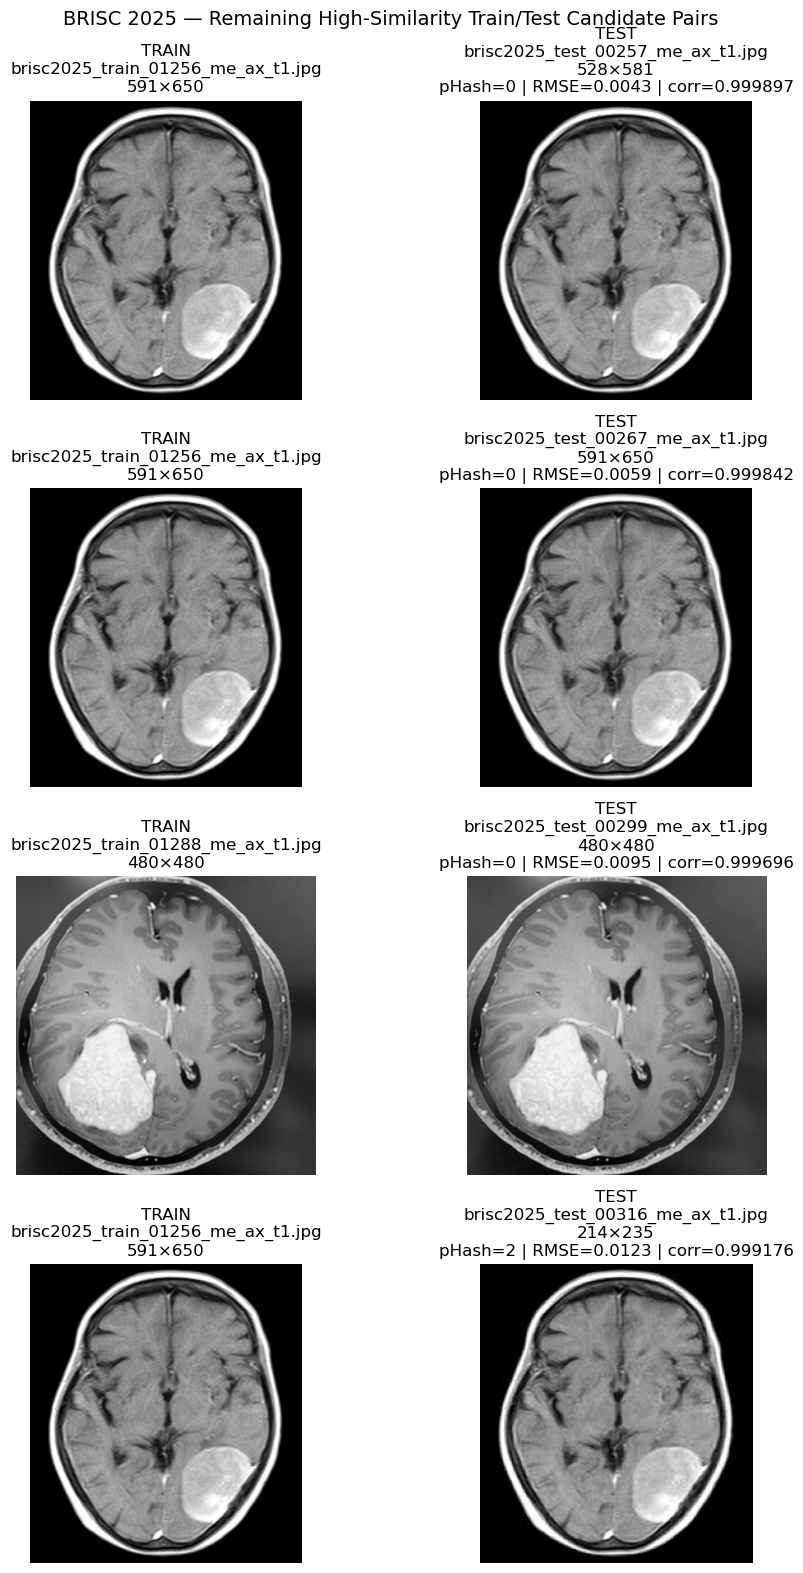

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\audit_remaining_high_similarity_train_test_pairs.png


In [15]:
import matplotlib.pyplot as plt

n_pairs = len(relevant_unconfirmed_df)

fig, axes = plt.subplots(
    n_pairs,
    2,
    figsize=(10, 4 * n_pairs)
)

if n_pairs == 1:
    axes = np.array([axes])

for plot_idx, (_, row) in enumerate(
    relevant_unconfirmed_df.iterrows()
):

    train_row = classification_df[
        classification_df["filename"] == row["train_filename"]
    ].iloc[0]

    test_row = classification_df[
        classification_df["filename"] == row["test_filename"]
    ].iloc[0]

    train_path = DATASET_ROOT / Path(
        train_row["relative_path"]
    )

    test_path = DATASET_ROOT / Path(
        test_row["relative_path"]
    )

    with Image.open(train_path) as img:
        train_img = np.asarray(img.convert("RGB"))

    with Image.open(test_path) as img:
        test_img = np.asarray(img.convert("RGB"))

    axes[plot_idx, 0].imshow(train_img)
    axes[plot_idx, 0].set_title(
        f"TRAIN\n{row['train_filename']}\n"
        f"{train_img.shape[1]}×{train_img.shape[0]}"
    )
    axes[plot_idx, 0].axis("off")

    axes[plot_idx, 1].imshow(test_img)
    axes[plot_idx, 1].set_title(
        f"TEST\n{row['test_filename']}\n"
        f"{test_img.shape[1]}×{test_img.shape[0]}\n"
        f"pHash={row['phash_distance']} | "
        f"RMSE={row['rmse']:.4f} | "
        f"corr={row['correlation']:.6f}"
    )
    axes[plot_idx, 1].axis("off")


plt.suptitle(
    "BRISC 2025 — Remaining High-Similarity "
    "Train/Test Candidate Pairs",
    fontsize=14
)

plt.tight_layout()

figure_path = (
    FIGURES_ROOT /
    "audit_remaining_high_similarity_train_test_pairs.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

## 5.2 Decision on Remaining High-Similarity Candidates

Native-resolution analysis and visual inspection were performed on the four
high-similarity train–test candidate pairs that remained after exact-content
cleaning.

None of the four pairs were byte- or pixel-identical at native resolution.
However, the pairs showed extremely high image correlation
(approximately 0.9992–0.9999), very small normalized RMSE values, and visually
matching anatomical structures and tumor morphology.

Three test images corresponded closely to a single training image
(`brisc2025_train_01256_me_ax_t1.jpg`) at different resolutions or encodings.
A second training image (`brisc2025_train_01288_me_ax_t1.jpg`) similarly matched
a test image with the same native dimensions but minor pixel-level differences.

These cases are therefore treated conservatively as image-level
near-duplicate/derivative content rather than independent MRI samples.

The two affected training images are excluded from the model-development pool.
The official BRISC test set remains unchanged.

This decision concerns image-level content leakage only and does not imply
patient-level identity, because reliable patient identifiers are unavailable.

In [16]:
# ------------------------------------------------------------
# Exclude confirmed derivative / near-duplicate training images
# ------------------------------------------------------------

derivative_exclusion_filenames = {
    "brisc2025_train_01256_me_ax_t1.jpg",
    "brisc2025_train_01288_me_ax_t1.jpg"
}

derivative_exclusion_df = unique_development_df[
    unique_development_df["filename"].isin(
        derivative_exclusion_filenames
    )
].copy()

print("DERIVATIVE / NEAR-DUPLICATE EXCLUSIONS")
print("-" * 70)

print(
    "Training records identified:",
    len(derivative_exclusion_df)
)

display(
    derivative_exclusion_df[
        [
            "filename",
            "tumor_label",
            "plane_label",
            "relative_path"
        ]
    ]
)


final_development_df = unique_development_df[
    ~unique_development_df["filename"].isin(
        derivative_exclusion_filenames
    )
].copy()

final_development_df = (
    final_development_df
    .reset_index(drop=True)
)


print("\nFINAL DEVELOPMENT POOL")
print("-" * 70)

print(
    "Before derivative exclusions:",
    len(unique_development_df)
)

print(
    "Derivative exclusions:",
    len(derivative_exclusion_df)
)

print(
    "Final development records:",
    len(final_development_df)
)

print(
    "Unique decoded fingerprints:",
    final_development_df[
        "decoded_rgb_sha256"
    ].nunique()
)

print("\nFINAL CLASS DISTRIBUTION")

display(
    final_development_df[
        "tumor_label"
    ]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

DERIVATIVE / NEAR-DUPLICATE EXCLUSIONS
----------------------------------------------------------------------
Training records identified: 2


,filename,tumor_label,plane_label,relative_path
726,brisc2025_train_01288_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...
4666,brisc2025_train_01256_me_ax_t1.jpg,meningioma,axial,classification_task\train\meningioma\brisc2025...



FINAL DEVELOPMENT POOL
----------------------------------------------------------------------
Before derivative exclusions: 4864
Derivative exclusions: 2
Final development records: 4862
Unique decoded fingerprints: 4862

FINAL CLASS DISTRIBUTION


,records
tumor_label,
glioma,1147
meningioma,1217
no_tumor,1058
pituitary,1440


In [17]:
derivative_exclusion_path = (
    INTERIM_ROOT /
    "classification_confirmed_derivative_training_exclusions.csv"
)

final_dev_path = (
    INTERIM_ROOT /
    "classification_final_leakage_controlled_development_pool.csv"
)

remaining_candidate_audit_path = (
    INTERIM_ROOT /
    "classification_remaining_similarity_candidate_audit.csv"
)

derivative_exclusion_df.to_csv(
    derivative_exclusion_path,
    index=False
)

final_development_df.to_csv(
    final_dev_path,
    index=False
)

native_verification_df.to_csv(
    remaining_candidate_audit_path,
    index=False
)

print("Saved:")
print(derivative_exclusion_path)
print(final_dev_path)
print(remaining_candidate_audit_path)

print("\nFiles exist:")
print(derivative_exclusion_path.exists())
print(final_dev_path.exists())
print(remaining_candidate_audit_path.exists())

Saved:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_confirmed_derivative_training_exclusions.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_final_leakage_controlled_development_pool.csv
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\interim\classification_remaining_similarity_candidate_audit.csv

Files exist:
True
True
True


## 6. Pre-Split Sanity Verification

Before constructing the training and validation subsets, the finalized
development pool is checked for residual exact-content overlap with the
official test set, duplicate decoded-image fingerprints, missing metadata,
and suitability of the proposed class-and-plane stratification scheme.

The validation split will only be constructed after these checks pass.

In [18]:
# ------------------------------------------------------------
# Pre-split sanity verification
# ------------------------------------------------------------

official_test_df = classification_df[
    classification_df["split"] == "test"
].copy()

print("PRE-SPLIT SANITY VERIFICATION")
print("-" * 70)

# 1. Final pool size
print(
    "Final development records:",
    len(final_development_df)
)

# 2. Exact decoded-content uniqueness
unique_dev_fingerprints = (
    final_development_df[
        "decoded_rgb_sha256"
    ].nunique()
)

print(
    "Unique development fingerprints:",
    unique_dev_fingerprints
)

print(
    "Duplicate fingerprints remaining:",
    len(final_development_df)
    - unique_dev_fingerprints
)

# 3. Exact decoded-content overlap with official test
development_fingerprints = set(
    final_development_df[
        "decoded_rgb_sha256"
    ]
)

test_fingerprints = set(
    official_test_df[
        "decoded_rgb_sha256"
    ]
)

residual_exact_overlap = (
    development_fingerprints &
    test_fingerprints
)

print(
    "Residual exact-content overlap with test:",
    len(residual_exact_overlap)
)

# 4. Confirm the two derivative exclusions are absent
remaining_derivative_records = (
    final_development_df[
        final_development_df[
            "filename"
        ].isin(derivative_exclusion_filenames)
    ]
)

print(
    "Excluded derivative records still present:",
    len(remaining_derivative_records)
)

# 5. Missing metadata
print(
    "Missing tumor labels:",
    final_development_df[
        "tumor_label"
    ].isna().sum()
)

print(
    "Missing stratification-plane labels:",
    final_development_df[
        "plane_for_stratification"
    ].isna().sum()
)

# ------------------------------------------------------------
# Construct proposed composite stratification label
# ------------------------------------------------------------

final_development_df[
    "stratification_label"
] = (
    final_development_df["tumor_label"].astype(str)
    + "__"
    + final_development_df[
        "plane_for_stratification"
    ].astype(str)
)

stratum_counts = (
    final_development_df[
        "stratification_label"
    ]
    .value_counts()
    .sort_index()
)

print("\nCLASS × PLANE STRATIFICATION COUNTS")
print("-" * 70)

display(
    stratum_counts
    .rename("records")
    .to_frame()
)

print(
    "\nNumber of strata:",
    len(stratum_counts)
)

print(
    "Smallest stratum:",
    int(stratum_counts.min())
)

# ------------------------------------------------------------
# Hard assertions
# ------------------------------------------------------------

assert len(final_development_df) == 4862
assert unique_dev_fingerprints == 4862
assert len(residual_exact_overlap) == 0
assert len(remaining_derivative_records) == 0
assert final_development_df["tumor_label"].isna().sum() == 0
assert (
    final_development_df[
        "plane_for_stratification"
    ].isna().sum()
    == 0
)

print("\nAll pre-split sanity checks PASSED.")

PRE-SPLIT SANITY VERIFICATION
----------------------------------------------------------------------
Final development records: 4862
Unique development fingerprints: 4862
Duplicate fingerprints remaining: 0
Residual exact-content overlap with test: 0
Excluded derivative records still present: 0
Missing tumor labels: 0
Missing stratification-plane labels: 0

CLASS × PLANE STRATIFICATION COUNTS
----------------------------------------------------------------------


,records
stratification_label,
glioma__axial,394
glioma__coronal,430
glioma__sagittal,323
meningioma__axial,348
meningioma__conflict,11
meningioma__coronal,400
meningioma__sagittal,458
no_tumor__axial,352
no_tumor__coronal,310



Number of strata: 13
Smallest stratum: 11

All pre-split sanity checks PASSED.


## 7. Reproducible Train/Validation Split Construction

The final leakage-controlled development pool contains 4,862 unique-content
classification images.

A fixed 80:20 train/validation split is constructed using a reproducible random
seed of 42.

Stratification is performed using the composite tumor-class and
MRI-plane audit label. For the 11 records derived from duplicate groups with
conflicting plane metadata, the special `conflict` category is retained rather
than assigning an arbitrary anatomical plane.

The official BRISC testing split is not involved in split construction and
remains unchanged for final evaluation.

In [19]:
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Fixed split configuration
# ------------------------------------------------------------

RANDOM_SEED = 42
VALIDATION_FRACTION = 0.20

# ------------------------------------------------------------
# Reproducible stratified split
# ------------------------------------------------------------

train_df, validation_df = train_test_split(
    final_development_df,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_SEED,
    stratify=final_development_df["stratification_label"]
)

train_df = (
    train_df
    .copy()
    .reset_index(drop=True)
)

validation_df = (
    validation_df
    .copy()
    .reset_index(drop=True)
)

train_df["model_split"] = "train"
validation_df["model_split"] = "validation"


print("TRAIN / VALIDATION SPLIT")
print("-" * 70)

print("Random seed:", RANDOM_SEED)
print("Validation fraction:", VALIDATION_FRACTION)

print("\nFinal development pool:", len(final_development_df))
print("Training records:", len(train_df))
print("Validation records:", len(validation_df))

print(
    "Split total:",
    len(train_df) + len(validation_df)
)

TRAIN / VALIDATION SPLIT
----------------------------------------------------------------------
Random seed: 42
Validation fraction: 0.2

Final development pool: 4862
Training records: 3889
Validation records: 973
Split total: 4862


In [20]:
print("CLASS DISTRIBUTION — TRAIN")
print("-" * 70)

display(
    train_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)


print("\nCLASS DISTRIBUTION — VALIDATION")
print("-" * 70)

display(
    validation_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)


# Percentage comparison

train_class_pct = (
    train_df["tumor_label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

validation_class_pct = (
    validation_df["tumor_label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

class_distribution_comparison = pd.DataFrame({
    "train_percent": train_class_pct,
    "validation_percent": validation_class_pct
})

class_distribution_comparison[
    "absolute_difference_pct_points"
] = (
    class_distribution_comparison[
        "train_percent"
    ]
    -
    class_distribution_comparison[
        "validation_percent"
    ]
).abs()

print("\nCLASS DISTRIBUTION PERCENTAGES")
print("-" * 70)

display(
    class_distribution_comparison.round(3)
)

CLASS DISTRIBUTION — TRAIN
----------------------------------------------------------------------


,records
tumor_label,
glioma,917
meningioma,973
no_tumor,847
pituitary,1152



CLASS DISTRIBUTION — VALIDATION
----------------------------------------------------------------------


,records
tumor_label,
glioma,230
meningioma,244
no_tumor,211
pituitary,288



CLASS DISTRIBUTION PERCENTAGES
----------------------------------------------------------------------


,train_percent,validation_percent,absolute_difference_pct_points
tumor_label,,,
glioma,23.579,23.638,0.059
meningioma,25.019,25.077,0.058
no_tumor,21.779,21.686,0.094
pituitary,29.622,29.599,0.023


In [21]:
print("CLASS × PLANE — TRAIN")
print("-" * 70)

train_strata = (
    train_df["stratification_label"]
    .value_counts()
    .sort_index()
    .rename("train_records")
)

display(train_strata.to_frame())


print("\nCLASS × PLANE — VALIDATION")
print("-" * 70)

validation_strata = (
    validation_df["stratification_label"]
    .value_counts()
    .sort_index()
    .rename("validation_records")
)

display(validation_strata.to_frame())


strata_comparison = pd.concat(
    [
        train_strata,
        validation_strata
    ],
    axis=1
).fillna(0)

strata_comparison["total"] = (
    strata_comparison["train_records"]
    +
    strata_comparison["validation_records"]
)

strata_comparison[
    "validation_percent"
] = (
    100
    * strata_comparison["validation_records"]
    / strata_comparison["total"]
)

print("\nSTRATIFICATION CHECK")
print("-" * 70)

display(
    strata_comparison.round(2)
)

CLASS × PLANE — TRAIN
----------------------------------------------------------------------


,train_records
stratification_label,
glioma__axial,315
glioma__coronal,344
glioma__sagittal,258
meningioma__axial,278
meningioma__conflict,9
meningioma__coronal,320
meningioma__sagittal,366
no_tumor__axial,282
no_tumor__coronal,248



CLASS × PLANE — VALIDATION
----------------------------------------------------------------------


,validation_records
stratification_label,
glioma__axial,79
glioma__coronal,86
glioma__sagittal,65
meningioma__axial,70
meningioma__conflict,2
meningioma__coronal,80
meningioma__sagittal,92
no_tumor__axial,70
no_tumor__coronal,62



STRATIFICATION CHECK
----------------------------------------------------------------------


,train_records,validation_records,total,validation_percent
stratification_label,,,,
glioma__axial,315,79,394,20.05
glioma__coronal,344,86,430,20.00
glioma__sagittal,258,65,323,20.12
meningioma__axial,278,70,348,20.11
meningioma__conflict,9,2,11,18.18
meningioma__coronal,320,80,400,20.00
meningioma__sagittal,366,92,458,20.09
no_tumor__axial,282,70,352,19.89
no_tumor__coronal,248,62,310,20.00


In [22]:
# ------------------------------------------------------------
# Fingerprint sets
# ------------------------------------------------------------

train_fingerprints = set(
    train_df["decoded_rgb_sha256"]
)

validation_fingerprints = set(
    validation_df["decoded_rgb_sha256"]
)

official_test_fingerprints = set(
    official_test_df["decoded_rgb_sha256"]
)

# ------------------------------------------------------------
# Pairwise overlap checks
# ------------------------------------------------------------

train_validation_overlap = (
    train_fingerprints
    &
    validation_fingerprints
)

train_test_overlap = (
    train_fingerprints
    &
    official_test_fingerprints
)

validation_test_overlap = (
    validation_fingerprints
    &
    official_test_fingerprints
)


print("FINAL CONTENT-LEAKAGE CHECK")
print("-" * 70)

print(
    "Train ↔ Validation exact-content overlap:",
    len(train_validation_overlap)
)

print(
    "Train ↔ Official Test exact-content overlap:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Official Test exact-content overlap:",
    len(validation_test_overlap)
)


# Verify filename membership also does not overlap

train_paths = set(train_df["relative_path"])
validation_paths = set(validation_df["relative_path"])

print(
    "\nTrain ↔ Validation path overlap:",
    len(train_paths & validation_paths)
)


# Hard assertions

assert len(train_df) + len(validation_df) == 4862

assert len(train_fingerprints) == len(train_df)
assert len(validation_fingerprints) == len(validation_df)

assert len(train_validation_overlap) == 0
assert len(train_test_overlap) == 0
assert len(validation_test_overlap) == 0

assert len(train_paths & validation_paths) == 0

print("\nAll final split leakage checks PASSED.")

FINAL CONTENT-LEAKAGE CHECK
----------------------------------------------------------------------
Train ↔ Validation exact-content overlap: 0
Train ↔ Official Test exact-content overlap: 0
Validation ↔ Official Test exact-content overlap: 0

Train ↔ Validation path overlap: 0

All final split leakage checks PASSED.


## 8. Export of Definitive Classification Split Manifests

The leakage-controlled train and validation subsets are now fixed.

The official BRISC test set remains unchanged and is reserved for final
evaluation. Exact split membership is exported to CSV so that every subsequent
preprocessing and modelling notebook uses identical records.

Final split sizes:

- Training: 3,889
- Validation: 973
- Official test: 1,000

The development split uses random seed 42 and an 80:20 validation protocol
stratified by tumor class and audited MRI-plane metadata.

In [23]:
# ------------------------------------------------------------
# Prepare definitive split manifests
# ------------------------------------------------------------

final_train_manifest = train_df.copy()
final_validation_manifest = validation_df.copy()

final_test_manifest = official_test_df.copy()
final_test_manifest["model_split"] = "test"

# Add a consistent stratification field to test for audit only
final_test_manifest["plane_for_stratification"] = (
    final_test_manifest["plane_label"]
)

final_test_manifest["stratification_label"] = (
    final_test_manifest["tumor_label"].astype(str)
    + "__"
    + final_test_manifest["plane_for_stratification"].astype(str)
)

# ------------------------------------------------------------
# Save individual manifests
# ------------------------------------------------------------

train_manifest_path = (
    PROCESSED_ROOT /
    "classification_train_manifest.csv"
)

validation_manifest_path = (
    PROCESSED_ROOT /
    "classification_validation_manifest.csv"
)

test_manifest_path = (
    PROCESSED_ROOT /
    "classification_test_manifest.csv"
)

final_train_manifest.to_csv(
    train_manifest_path,
    index=False
)

final_validation_manifest.to_csv(
    validation_manifest_path,
    index=False
)

final_test_manifest.to_csv(
    test_manifest_path,
    index=False
)

print("DEFINITIVE SPLIT MANIFESTS SAVED")
print("-" * 70)

print("Train:")
print(train_manifest_path)

print("\nValidation:")
print(validation_manifest_path)

print("\nTest:")
print(test_manifest_path)

print("\nFiles exist:")
print(train_manifest_path.exists())
print(validation_manifest_path.exists())
print(test_manifest_path.exists())

DEFINITIVE SPLIT MANIFESTS SAVED
----------------------------------------------------------------------
Train:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\classification_train_manifest.csv

Validation:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\classification_validation_manifest.csv

Test:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\classification_test_manifest.csv

Files exist:
True
True
True


In [24]:
# ------------------------------------------------------------
# Combined final split manifest
# ------------------------------------------------------------

final_classification_split_manifest = pd.concat(
    [
        final_train_manifest,
        final_validation_manifest,
        final_test_manifest
    ],
    ignore_index=True
)

print("FINAL CLASSIFICATION SPLIT MANIFEST")
print("-" * 70)

print(
    "Total retained records:",
    len(final_classification_split_manifest)
)

display(
    final_classification_split_manifest[
        "model_split"
    ]
    .value_counts()
    .rename("records")
    .to_frame()
)

print("\nCLASS × MODEL SPLIT")

display(
    pd.crosstab(
        final_classification_split_manifest[
            "tumor_label"
        ],
        final_classification_split_manifest[
            "model_split"
        ]
    )
)

master_split_path = (
    PROCESSED_ROOT /
    "classification_final_split_manifest.csv"
)

final_classification_split_manifest.to_csv(
    master_split_path,
    index=False
)

print("\nMaster split manifest saved to:")
print(master_split_path)

print(
    "File exists:",
    master_split_path.exists()
)

FINAL CLASSIFICATION SPLIT MANIFEST
----------------------------------------------------------------------
Total retained records: 5862


,records
model_split,
train,3889
test,1000
validation,973



CLASS × MODEL SPLIT


model_split,test,train,validation
tumor_label,,,
glioma,254,917,230
meningioma,306,973,244
no_tumor,140,847,211
pituitary,300,1152,288



Master split manifest saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\classification_final_split_manifest.csv
File exists: True


In [25]:
# ------------------------------------------------------------
# Build unified training-exclusion ledger
# ------------------------------------------------------------

exact_cross_test_exclusions = training_exclusion_df.copy()
exact_cross_test_exclusions["exclusion_reason"] = (
    "exact_decoded_content_overlap_with_official_test"
)

within_train_exclusions = (
    within_dev_duplicate_exclusions_df.copy()
)
within_train_exclusions["exclusion_reason"] = (
    "redundant_exact_duplicate_within_development_pool"
)

derivative_exclusions = derivative_exclusion_df.copy()
derivative_exclusions["exclusion_reason"] = (
    "confirmed_high_similarity_derivative_overlap_with_official_test"
)

exclusion_ledger_df = pd.concat(
    [
        exact_cross_test_exclusions,
        within_train_exclusions,
        derivative_exclusions
    ],
    ignore_index=True
)

print("FINAL TRAINING EXCLUSION LEDGER")
print("-" * 70)

print(
    "Total excluded official-training records:",
    len(exclusion_ledger_df)
)

display(
    exclusion_ledger_df[
        "exclusion_reason"
    ]
    .value_counts()
    .rename("records")
    .to_frame()
)

print("\nEXCLUSIONS BY CLASS")

display(
    pd.crosstab(
        exclusion_ledger_df["tumor_label"],
        exclusion_ledger_df["exclusion_reason"]
    )
)

exclusion_ledger_path = (
    PROCESSED_ROOT /
    "classification_training_exclusion_ledger.csv"
)

exclusion_ledger_df.to_csv(
    exclusion_ledger_path,
    index=False
)

print("\nExclusion ledger saved to:")
print(exclusion_ledger_path)

print(
    "File exists:",
    exclusion_ledger_path.exists()
)

FINAL TRAINING EXCLUSION LEDGER
----------------------------------------------------------------------
Total excluded official-training records: 138


,records
exclusion_reason,
exact_decoded_content_overlap_with_official_test,104
redundant_exact_duplicate_within_development_pool,32
confirmed_high_similarity_derivative_overlap_with_official_test,2



EXCLUSIONS BY CLASS


exclusion_reason,confirmed_high_similarity_derivative_overlap_with_official_test,exact_decoded_content_overlap_with_official_test,redundant_exact_duplicate_within_development_pool
tumor_label,,,
meningioma,2,97,13
no_tumor,0,0,9
pituitary,0,7,10



Exclusion ledger saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\classification_training_exclusion_ledger.csv
File exists: True


In [26]:
# ------------------------------------------------------------
# Final post-export verification
# ------------------------------------------------------------

saved_train = pd.read_csv(train_manifest_path)
saved_validation = pd.read_csv(validation_manifest_path)
saved_test = pd.read_csv(test_manifest_path)
saved_master = pd.read_csv(master_split_path)

print("POST-EXPORT VERIFICATION")
print("-" * 70)

print("Saved train records:", len(saved_train))
print("Saved validation records:", len(saved_validation))
print("Saved test records:", len(saved_test))
print("Saved master records:", len(saved_master))

# Path uniqueness across model splits
saved_train_paths = set(saved_train["relative_path"])
saved_val_paths = set(saved_validation["relative_path"])
saved_test_paths = set(saved_test["relative_path"])

print(
    "\nTrain ↔ Validation path overlap:",
    len(saved_train_paths & saved_val_paths)
)

print(
    "Train ↔ Test path overlap:",
    len(saved_train_paths & saved_test_paths)
)

print(
    "Validation ↔ Test path overlap:",
    len(saved_val_paths & saved_test_paths)
)

# Exact decoded-content overlap
saved_train_fp = set(saved_train["decoded_rgb_sha256"])
saved_val_fp = set(saved_validation["decoded_rgb_sha256"])
saved_test_fp = set(saved_test["decoded_rgb_sha256"])

print(
    "\nTrain ↔ Validation fingerprint overlap:",
    len(saved_train_fp & saved_val_fp)
)

print(
    "Train ↔ Test fingerprint overlap:",
    len(saved_train_fp & saved_test_fp)
)

print(
    "Validation ↔ Test fingerprint overlap:",
    len(saved_val_fp & saved_test_fp)
)

# Confirm previously identified derivative training images are absent
retained_dev_filenames = (
    set(saved_train["filename"])
    |
    set(saved_validation["filename"])
)

print(
    "\nExcluded derivative filenames retained:",
    len(
        retained_dev_filenames
        &
        derivative_exclusion_filenames
    )
)

# Hard assertions
assert len(saved_train) == 3889
assert len(saved_validation) == 973
assert len(saved_test) == 1000
assert len(saved_master) == 5862

assert len(saved_train_paths & saved_val_paths) == 0
assert len(saved_train_paths & saved_test_paths) == 0
assert len(saved_val_paths & saved_test_paths) == 0

assert len(saved_train_fp & saved_val_fp) == 0
assert len(saved_train_fp & saved_test_fp) == 0
assert len(saved_val_fp & saved_test_fp) == 0

assert (
    len(
        retained_dev_filenames
        &
        derivative_exclusion_filenames
    )
    == 0
)

print("\nAll exported split checks PASSED.")

POST-EXPORT VERIFICATION
----------------------------------------------------------------------
Saved train records: 3889
Saved validation records: 973
Saved test records: 1000
Saved master records: 5862

Train ↔ Validation path overlap: 0
Train ↔ Test path overlap: 0
Validation ↔ Test path overlap: 0

Train ↔ Validation fingerprint overlap: 0
Train ↔ Test fingerprint overlap: 0
Validation ↔ Test fingerprint overlap: 0

Excluded derivative filenames retained: 0

All exported split checks PASSED.


# 9. Final Split-Preparation Summary

A reproducible leakage-controlled classification protocol was constructed from
the BRISC 2025 dataset.

## 9.1 Duplicate and Leakage Control

All 6,000 classification images were systematically fingerprinted using their
decoded RGB pixel content and native dimensions.

This procedure identified exact visual-content duplication that could not always
be detected through file-level hashes alone.

The official training set originally contained 5,000 records.

The following records were excluded from the primary model-development data:

- **104 records** whose exact decoded image content also occurred in the
  official BRISC test split.
- **32 redundant records** belonging to exact duplicate-content groups entirely
  within the remaining development data.
- **2 additional training records** showing extremely high visual similarity to
  official test images and judged, after quantitative and visual inspection, to
  represent derivative or near-duplicate image content.

No raw BRISC files were deleted, renamed, or modified. All exclusion decisions
are represented through reproducible metadata and audit tables.

## 9.2 Final Development Dataset

After leakage control and exact-content deduplication, the classification
development pool contains **4,862 unique-content images**:

- Glioma: 1,147
- Meningioma: 1,217
- No-tumor: 1,058
- Pituitary: 1,440

No duplicate decoded-image fingerprints remain within this development pool.

## 9.3 Train and Validation Construction

The 4,862-image development pool was divided using:

- Training fraction: 80%
- Validation fraction: 20%
- Random seed: 42
- Stratification: tumor class combined with audited MRI-plane metadata

The resulting subsets contain:

- **Training: 3,889 images**
- **Validation: 973 images**

Class proportions and class-by-plane distributions are closely preserved
between training and validation.

Eleven records derived from duplicate groups with inconsistent MRI-plane
metadata were represented using a dedicated `conflict` audit category rather
than assigning an arbitrary anatomical plane.

## 9.4 Official Test Set

The official BRISC classification test set remains unchanged:

- **Official test: 1,000 images**

The test set was not used for validation construction or hyperparameter
selection.

## 9.5 Final Leakage Verification

Post-export verification confirmed:

- zero path overlap between training, validation, and test subsets;
- zero exact decoded-content fingerprint overlap between training and
  validation;
- zero exact decoded-content fingerprint overlap between training and the
  official test set;
- zero exact decoded-content fingerprint overlap between validation and the
  official test set;
- exclusion of both conservatively identified derivative training images.

Therefore, the exported manifests define the fixed classification data protocol
to be used consistently in all subsequent preprocessing, training, validation,
model comparison, and explainability experiments.

# Notebook 4 — Conclusion

Leakage-aware classification split preparation is complete.

The final train, validation, and official test manifests have been exported,
audited, and independently reloaded for post-export verification.

All subsequent modelling notebooks must use these saved manifests rather than
reconstructing or randomly resplitting the BRISC classification dataset.

The project can now proceed to reproducible image and mask preprocessing.